# 📊 Báo cáo EDA Tổng quan Bộ Dữ liệu Thương mại Điện tử Olist (Brazil)
**Dự án:** Xây dựng mô hình phân khúc khách hàng thương mại điện tử Olist  
**Nhiệm vụ:** A02 – Khám phá & Đọc dữ liệu Olist (Kiểm tra Schema, Khóa liên kết, Phân phối & Hành vi cốt lõi)  
**Phụ trách chính:** Thành viên A (Trưởng nhóm / Kỹ sư dữ liệu & Mô hình hóa)  
**Phối hợp:** Thành viên B (Trải nghiệm), Thành viên C (Loyalty & RFM)  

---

### Mục tiêu của Notebook:
1. Đọc và kiểm tra cấu trúc 9 bảng dữ liệu Olist trong thư mục `data/raw/`.
2. Kiểm tra tính toàn vẹn của dữ liệu: kích thước (shape), kiểu dữ liệu (dtypes), giá trị thiếu (null values), tính duy nhất của khóa chính (Primary Keys).
3. Làm rõ cơ chế liên kết giữa các bảng, đặc biệt là sự khác biệt giữa `customer_id` và `customer_unique_id`.
4. Phân tích phân phối của các biến quan trọng: trạng thái đơn hàng, xu hướng doanh số theo thời gian, hành vi mua lặp, phương thức thanh toán và điểm đánh giá dịch vụ.
5. Đúc kết các insight then chốt làm tiền đề cho giai đoạn Tiền xử lý (A03, A04) và Trích xuất đặc trưng (B03-B05, C04-C05).

In [1]:
# 1. Cấu hình & Import thư viện dùng chung
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Cấu hình hiển thị của Pandas và biểu đồ
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

print("✅ Đã nạp thành công các thư viện phân tích!")

✅ Đã nạp thành công các thư viện phân tích!


## 2. Đọc 9 Bảng Dữ liệu Olist từ `data/raw/`
Chúng ta áp dụng đúng **Quy ước đặt tên biến**: Tất cả các bảng `DataFrame` đều có tiền tố `df_` kèm tên bảng rõ nghĩa.

In [2]:
# Đường dẫn tới thư mục dữ liệu gốc
DATA_RAW_DIR = Path("../data/raw")
if not DATA_RAW_DIR.exists():
    DATA_RAW_DIR = Path("data/raw")  # Hỗ trợ cả khi chạy từ thư mục gốc hoặc thư mục notebooks

# Đọc lần lượt 9 bảng dữ liệu
df_customers = pd.read_csv(DATA_RAW_DIR / "olist_customers_dataset.csv")
df_orders = pd.read_csv(DATA_RAW_DIR / "olist_orders_dataset.csv")
df_order_items = pd.read_csv(DATA_RAW_DIR / "olist_order_items_dataset.csv")
df_payments = pd.read_csv(DATA_RAW_DIR / "olist_order_payments_dataset.csv")
df_reviews = pd.read_csv(DATA_RAW_DIR / "olist_order_reviews_dataset.csv")
df_products = pd.read_csv(DATA_RAW_DIR / "olist_products_dataset.csv")
df_sellers = pd.read_csv(DATA_RAW_DIR / "olist_sellers_dataset.csv")
df_geolocation = pd.read_csv(DATA_RAW_DIR / "olist_geolocation_dataset.csv")
df_translation = pd.read_csv(DATA_RAW_DIR / "product_category_name_translation.csv")

# Tổng hợp thông tin cơ bản về 9 bảng dữ liệu
datasets_summary = [
    {"Tên bảng": "olist_customers", "DataFrame": "df_customers", "Số dòng": len(df_customers), "Số cột": df_customers.shape[1], "Khóa chính (dự kiến)": "customer_id"},
    {"Tên bảng": "olist_orders", "DataFrame": "df_orders", "Số dòng": len(df_orders), "Số cột": df_orders.shape[1], "Khóa chính (dự kiến)": "order_id"},
    {"Tên bảng": "olist_order_items", "DataFrame": "df_order_items", "Số dòng": len(df_order_items), "Số cột": df_order_items.shape[1], "Khóa chính (dự kiến)": "order_id + order_item_id"},
    {"Tên bảng": "olist_order_payments", "DataFrame": "df_payments", "Số dòng": len(df_payments), "Số cột": df_payments.shape[1], "Khóa chính (dự kiến)": "order_id + payment_sequential"},
    {"Tên bảng": "olist_order_reviews", "DataFrame": "df_reviews", "Số dòng": len(df_reviews), "Số cột": df_reviews.shape[1], "Khóa chính (dự kiến)": "review_id (+ order_id)"},
    {"Tên bảng": "olist_products", "DataFrame": "df_products", "Số dòng": len(df_products), "Số cột": df_products.shape[1], "Khóa chính (dự kiến)": "product_id"},
    {"Tên bảng": "olist_sellers", "DataFrame": "df_sellers", "Số dòng": len(df_sellers), "Số cột": df_sellers.shape[1], "Khóa chính (dự kiến)": "seller_id"},
    {"Tên bảng": "olist_geolocation", "DataFrame": "df_geolocation", "Số dòng": len(df_geolocation), "Số cột": df_geolocation.shape[1], "Khóa chính (dự kiến)": "geolocation_zip_code_prefix"},
    {"Tên bảng": "category_translation", "DataFrame": "df_translation", "Số dòng": len(df_translation), "Số cột": df_translation.shape[1], "Khóa chính (dự kiến)": "product_category_name"},
]

df_summary = pd.DataFrame(datasets_summary)
display(df_summary)

,Tên bảng,DataFrame,Số dòng,Số cột,Khóa chính (dự kiến)
0,olist_customers,df_customers,99441,5,customer_id
1,olist_orders,df_orders,99441,8,order_id
2,olist_order_items,df_order_items,112650,7,order_id + order_item_id
3,olist_order_payments,df_payments,103886,5,order_id + payment_sequential
4,olist_order_reviews,df_reviews,99224,7,review_id (+ order_id)
5,olist_products,df_products,32951,9,product_id
6,olist_sellers,df_sellers,3095,4,seller_id
7,olist_geolocation,df_geolocation,1000163,5,geolocation_zip_code_prefix
8,category_translation,df_translation,71,2,product_category_name


## 3. Kiểm tra Tính toàn vẹn Dữ liệu & Sơ đồ Khóa Liên kết (Keys Check)

### 3.1. Phân biệt then chốt: `customer_id` vs `customer_unique_id`
Trong tập dữ liệu Olist:
- `customer_id`: Là mã định danh cho **từng lần mua hàng / từng giao dịch đơn**. Mỗi đơn hàng luôn sinh ra một `customer_id` mới.
- `customer_unique_id`: Là mã định danh **duy nhất của khách hàng thực tế ngoài đời**.
👉 **Quy tắc vàng cho bài toán phân cụm khách hàng (A, B, C):** Toàn bộ phân tích RFM, hành vi, gom cụm bắt buộc phải nhóm theo `customer_unique_id`!

In [3]:
# Kiểm tra số lượng khách hàng duy nhất và tính mua lặp lại
total_customer_rows = len(df_customers)
unique_customers = df_customers['customer_unique_id'].nunique()
repeat_customers_count = (df_customers['customer_unique_id'].value_counts() > 1).sum()
repeat_customers_pct = (repeat_customers_count / unique_customers) * 100

print(f"Tổng số bản ghi trong bảng customers: {total_customer_rows:,}")
print(f"Số lượng khách hàng thực tế duy nhất (customer_unique_id): {unique_customers:,}")
print(f"Số khách hàng có từ 2 đơn hàng trở lên (mua lặp lại): {repeat_customers_count:,} ({repeat_customers_pct:.2f}%)")
print(f"Tỷ lệ khách hàng chỉ mua đúng 1 lần: {100 - repeat_customers_pct:.2f}%")

Tổng số bản ghi trong bảng customers: 99,441
Số lượng khách hàng thực tế duy nhất (customer_unique_id): 96,096
Số khách hàng có từ 2 đơn hàng trở lên (mua lặp lại): 2,997 (3.12%)
Tỷ lệ khách hàng chỉ mua đúng 1 lần: 96.88%


In [4]:
# Kiểm tra tính duy nhất của các khóa chính và tỷ lệ thiếu dữ liệu
print("=== KIỂM TRA TÍNH DUY NHẤT CỦA CÁC KHÓA CHÍNH ===")
print(f"orders['order_id'] duy nhất: {df_orders['order_id'].is_unique} ({df_orders['order_id'].nunique():,} / {len(df_orders):,})")
print(f"customers['customer_id'] duy nhất: {df_customers['customer_id'].is_unique} ({df_customers['customer_id'].nunique():,} / {len(df_customers):,})")
print(f"products['product_id'] duy nhất: {df_products['product_id'].is_unique} ({df_products['product_id'].nunique():,} / {len(df_products):,})")
print(f"sellers['seller_id'] duy nhất: {df_sellers['seller_id'].is_unique} ({df_sellers['seller_id'].nunique():,} / {len(df_sellers):,})")

# Kiểm tra missing values trên các bảng quan trọng
print("\n=== GIÁ TRỊ THIẾU (NULL) Ở CÁC CỘT QUAN TRỌNG ===")
print("1. Bảng df_orders:\n", df_orders.isnull().sum()[df_orders.isnull().sum() > 0])
print("\n2. Bảng df_products:\n", df_products.isnull().sum()[df_products.isnull().sum() > 0])
print("\n3. Bảng df_reviews:\n", df_reviews.isnull().sum()[df_reviews.isnull().sum() > 0])

=== KIỂM TRA TÍNH DUY NHẤT CỦA CÁC KHÓA CHÍNH ===
orders['order_id'] duy nhất: True (99,441 / 99,441)
customers['customer_id'] duy nhất: True (99,441 / 99,441)
products['product_id'] duy nhất: True (32,951 / 32,951)
sellers['seller_id'] duy nhất: True (3,095 / 3,095)

=== GIÁ TRỊ THIẾU (NULL) Ở CÁC CỘT QUAN TRỌNG ===
1. Bảng df_orders:
 order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

2. Bảng df_products:
 product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

3. Bảng df_reviews:
 review_comment_title      87656
review_comment_message    58247
dtype: int64


## 4. Phân tích Chi tiết Bảng Đơn Hàng (`df_orders`)
Bảng `df_orders` đóng vai trò là xương sống kết nối toàn bộ hành vi mua sắm, thời gian giao hàng và trạng thái đơn.

,Số lượng,Tỷ lệ (%)
order_status,,
delivered,96478,97.02
shipped,1107,1.11
canceled,625,0.63
unavailable,609,0.61
invoiced,314,0.32
processing,301,0.30
created,5,0.01
approved,2,0.00


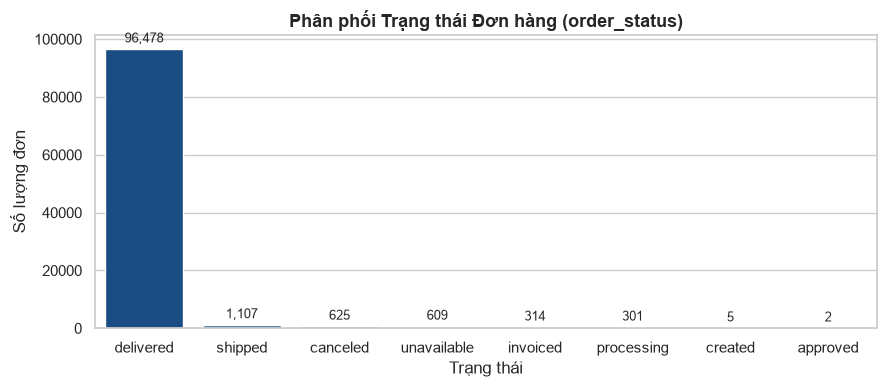

👉 Insight: Đơn hàng 'delivered' chiếm 97.02%. Trong các bước làm sạch tiếp theo (A03-A04), nhóm chỉ giữ lại các đơn 'delivered' để đảm bảo phân tích hành vi và thời gian giao hàng chính xác.


In [5]:
# 4.1. Phân phối trạng thái đơn hàng (order_status)
order_status_counts = df_orders['order_status'].value_counts()
order_status_pct = df_orders['order_status'].value_counts(normalize=True) * 100

df_status_summary = pd.DataFrame({"Số lượng": order_status_counts, "Tỷ lệ (%)": order_status_pct})
display(df_status_summary)

plt.figure(figsize=(9, 4))
ax = sns.barplot(x=order_status_counts.index, y=order_status_counts.values, hue=order_status_counts.index, palette="Blues_r", legend=False)
plt.title("Phân phối Trạng thái Đơn hàng (order_status)", fontsize=13, fontweight='bold')
plt.xlabel("Trạng thái")
plt.ylabel("Số lượng đơn")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points')
plt.tight_layout()
plt.show()

print("👉 Insight: Đơn hàng 'delivered' chiếm 97.02%. Trong các bước làm sạch tiếp theo (A03-A04), nhóm chỉ giữ lại các đơn 'delivered' để đảm bảo phân tích hành vi và thời gian giao hàng chính xác.")

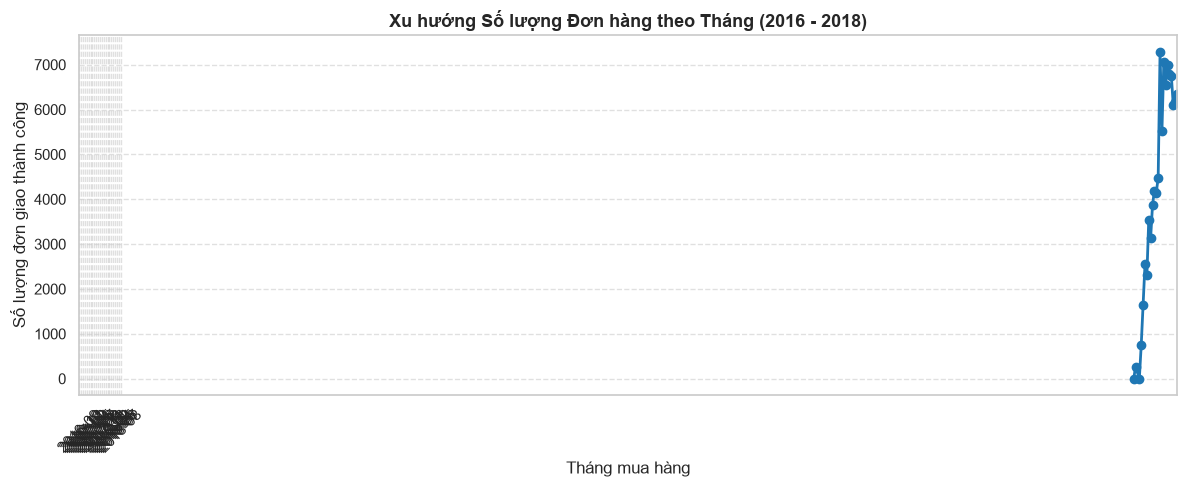

Khoảng thời gian giao dịch: từ 2016-09-04 đến 2018-10-17
👉 Tháng 11/2017 có lượng đơn tăng đột biến do sự kiện Black Friday.


In [6]:
# 4.2. Chuyển đổi định dạng thời gian & Xu hướng mua sắm theo tháng
datetime_cols = [
    'order_purchase_timestamp', 'order_approved_at', 
    'order_delivered_carrier_date', 'order_delivered_customer_date', 
    'order_estimated_delivery_date'
]

for col in datetime_cols:
    df_orders[col] = pd.to_datetime(df_orders[col], errors='coerce')

# Lọc các đơn delivered và phân tích số lượng đơn theo tháng
df_delivered = df_orders[df_orders['order_status'] == 'delivered'].copy()
df_delivered['purchase_year_month'] = df_delivered['order_purchase_timestamp'].dt.to_period('M')

monthly_orders = df_delivered['purchase_year_month'].value_counts().sort_index()

plt.figure(figsize=(12, 5))
monthly_orders.plot(kind='line', marker='o', color='#1f77b4', linewidth=2)
plt.title("Xu hướng Số lượng Đơn hàng theo Tháng (2016 - 2018)", fontsize=13, fontweight='bold')
plt.xlabel("Tháng mua hàng")
plt.ylabel("Số lượng đơn giao thành công")
plt.xticks(range(len(monthly_orders)), [str(p) for p in monthly_orders.index], rotation=45)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

print(f"Khoảng thời gian giao dịch: từ {df_orders['order_purchase_timestamp'].min().strftime('%Y-%m-%d')} đến {df_orders['order_purchase_timestamp'].max().strftime('%Y-%m-%d')}")
print("👉 Tháng 11/2017 có lượng đơn tăng đột biến do sự kiện Black Friday.")

Thời gian giao hàng trung bình: 10.2 ngày (Trung vị)
Tỷ lệ đơn hàng giao trễ hạn: 8.11% (7,826 đơn)


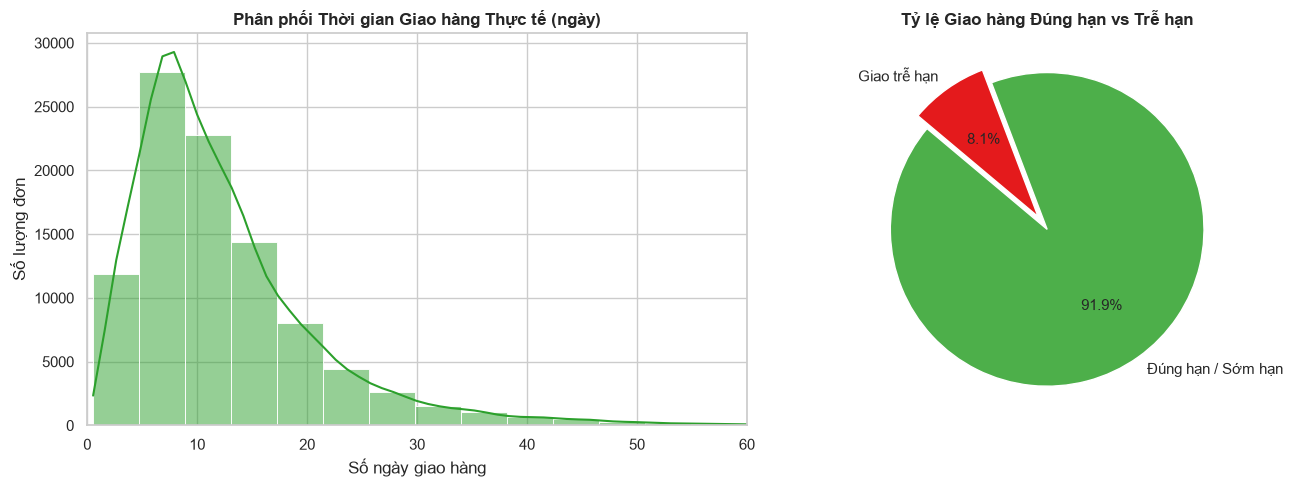

In [7]:
# 4.3. Phân tích thời gian giao hàng thực tế vs dự kiến (Hỗ trợ Thành viên B)
# Thời gian giao hàng thực tế (ngày) = ngày khách nhận - ngày mua
df_delivered['delivery_duration_days'] = (
    df_delivered['order_delivered_customer_date'] - df_delivered['order_purchase_timestamp']
).dt.total_seconds() / (24 * 3600)

# Số ngày giao trễ so với dự kiến: > 0 là trễ, <= 0 là đúng hạn/sớm hơn
df_delivered['delay_days'] = (
    df_delivered['order_delivered_customer_date'] - df_delivered['order_estimated_delivery_date']
).dt.total_seconds() / (24 * 3600)

df_delivered['is_delayed'] = df_delivered['delay_days'] > 0

delayed_count = df_delivered['is_delayed'].sum()
delayed_pct = df_delivered['is_delayed'].mean() * 100

print(f"Thời gian giao hàng trung bình: {df_delivered['delivery_duration_days'].median():.1f} ngày (Trung vị)")
print(f"Tỷ lệ đơn hàng giao trễ hạn: {delayed_pct:.2f}% ({delayed_count:,} đơn)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ thời gian giao hàng (giới hạn < 60 ngày để quan sát rõ phân phối)
sns.histplot(df_delivered['delivery_duration_days'].dropna(), bins=50, kde=True, ax=axes[0], color='#2ca02c')
axes[0].set_xlim(0, 60)
axes[0].set_title("Phân phối Thời gian Giao hàng Thực tế (ngày)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Số ngày giao hàng")
axes[0].set_ylabel("Số lượng đơn")

# Biểu đồ tỷ lệ giao đúng hạn vs trễ hạn
axes[1].pie([len(df_delivered) - delayed_count, delayed_count], 
            labels=['Đúng hạn / Sớm hạn', 'Giao trễ hạn'], 
            autopct='%1.1f%%', colors=['#4daf4a', '#e41a1c'], startangle=140, explode=[0, 0.1])
axes[1].set_title("Tỷ lệ Giao hàng Đúng hạn vs Trễ hạn", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

## 5. Phân tích Giá trị Đơn hàng & Thanh toán (`df_payments`)
Hỗ trợ trực tiếp cho **Thành viên C** (tính chỉ số Monetary trong RFM và hình thức thanh toán).

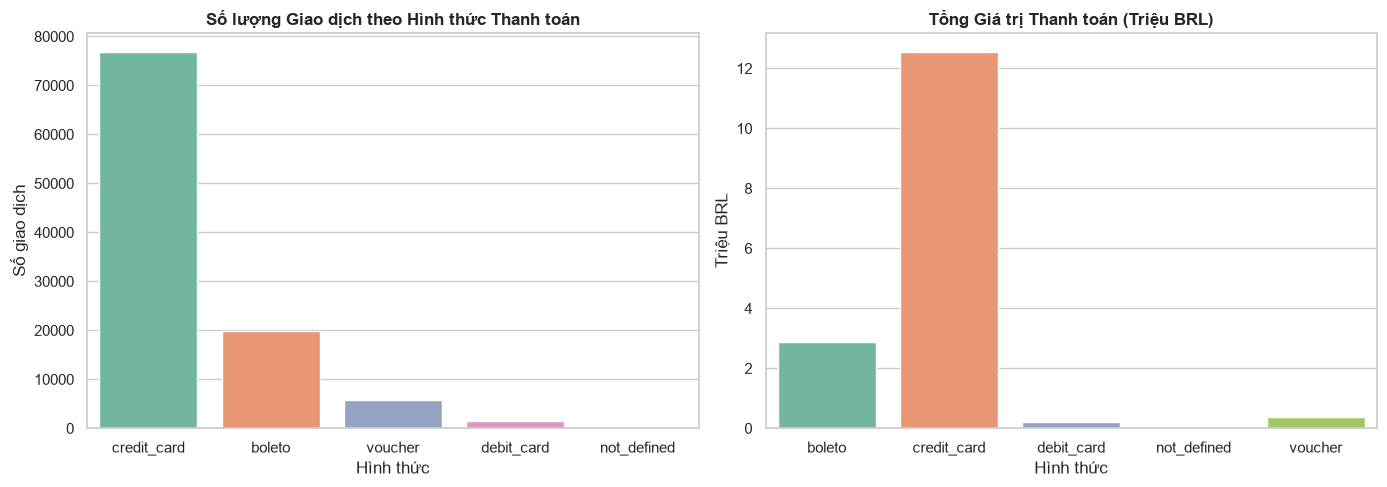

👉 Thẻ tín dụng (Credit Card) áp đảo cả về số lượng (~74%) và tổng giá trị thanh toán (~78%). Boleto (hình thức thanh toán qua mã phiếu tại Brazil) đứng thứ 2.


In [8]:
# 5.1. Phân loại hình thức thanh toán
payment_type_counts = df_payments['payment_type'].value_counts()
payment_value_sum = df_payments.groupby('payment_type')['payment_value'].sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Số lượng giao dịch theo hình thức
sns.barplot(x=payment_type_counts.index, y=payment_type_counts.values, hue=payment_type_counts.index, ax=axes[0], palette="Set2", legend=False)
axes[0].set_title("Số lượng Giao dịch theo Hình thức Thanh toán", fontweight='bold')
axes[0].set_xlabel("Hình thức")
axes[0].set_ylabel("Số giao dịch")

# Tổng giá trị giao dịch theo hình thức
sns.barplot(x=payment_value_sum.index, y=payment_value_sum.values / 1e6, hue=payment_value_sum.index, ax=axes[1], palette="Set2", legend=False)
axes[1].set_title("Tổng Giá trị Thanh toán (Triệu BRL)", fontweight='bold')
axes[1].set_xlabel("Hình thức")
axes[1].set_ylabel("Triệu BRL")

plt.tight_layout()
plt.show()

print("👉 Thẻ tín dụng (Credit Card) áp đảo cả về số lượng (~74%) và tổng giá trị thanh toán (~78%). Boleto (hình thức thanh toán qua mã phiếu tại Brazil) đứng thứ 2.")

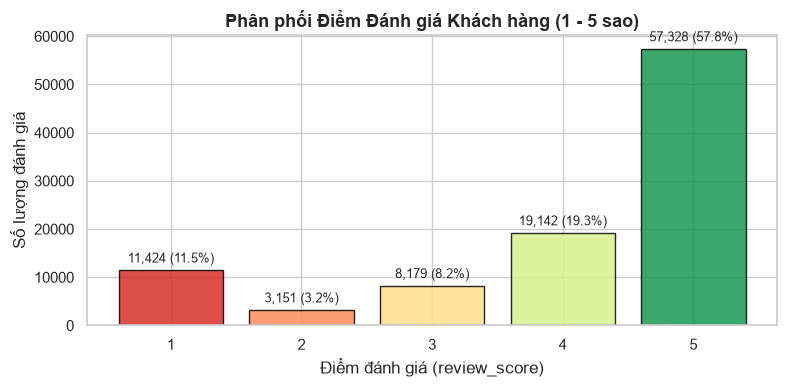

Tỷ lệ hài lòng (4-5 sao): 77.07%
Tỷ lệ không hài lòng (1-2 sao): 14.69%


In [9]:
# 5.2. Phân tích Điểm Đánh giá Trải nghiệm (df_reviews - Hỗ trợ Thành viên B)
review_counts = df_reviews['review_score'].value_counts().sort_index()

plt.figure(figsize=(8, 4))
colors = ['#d73027', '#fc8d59', '#fee08b', '#d9ef8b', '#1a9850']
bars = plt.bar(review_counts.index, review_counts.values, color=colors, edgecolor='black', alpha=0.85)
plt.title("Phân phối Điểm Đánh giá Khách hàng (1 - 5 sao)", fontsize=13, fontweight='bold')
plt.xlabel("Điểm đánh giá (review_score)")
plt.ylabel("Số lượng đánh giá")
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 1000, f"{yval:,} ({yval/len(df_reviews)*100:.1f}%)", ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

good_reviews = df_reviews['review_score'].isin([4, 5]).mean() * 100
bad_reviews = df_reviews['review_score'].isin([1, 2]).mean() * 100
print(f"Tỷ lệ hài lòng (4-5 sao): {good_reviews:.2f}%")
print(f"Tỷ lệ không hài lòng (1-2 sao): {bad_reviews:.2f}%")

## 6. Phân tích Khách hàng & Địa lý (`df_customers`)
Khảo sát phân bố địa lý của khách hàng trên toàn lãnh thổ Brazil.

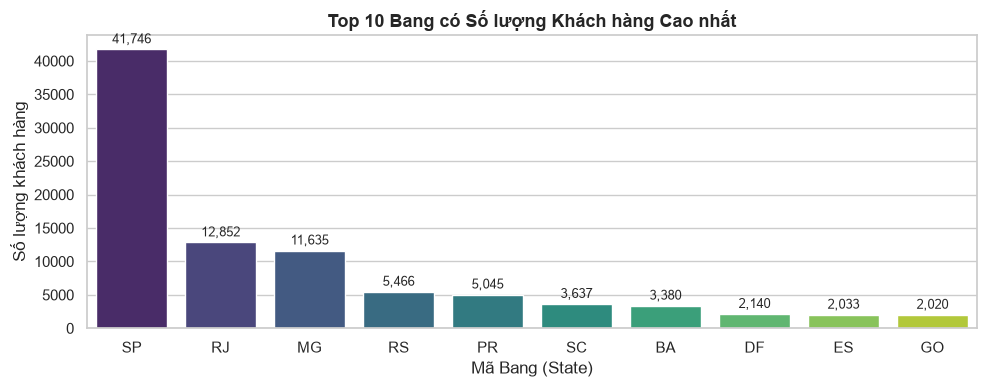

👉 Bang São Paulo (SP) chiếm tới 42.0% tổng số khách hàng của Olist, tiếp theo là Rio de Janeiro (RJ) và Minas Gerais (MG).


In [10]:
# Top 10 Bang tập trung nhiều khách hàng nhất
top_states = df_customers['customer_state'].value_counts().head(10)

plt.figure(figsize=(10, 4))
sns.barplot(x=top_states.index, y=top_states.values, hue=top_states.index, palette="viridis", legend=False)
plt.title("Top 10 Bang có Số lượng Khách hàng Cao nhất", fontsize=13, fontweight='bold')
plt.xlabel("Mã Bang (State)")
plt.ylabel("Số lượng khách hàng")
for i, v in enumerate(top_states.values):
    plt.text(i, v + 500, f"{v:,}", ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

sp_pct = (df_customers['customer_state'] == 'SP').mean() * 100
print(f"👉 Bang São Paulo (SP) chiếm tới {sp_pct:.1f}% tổng số khách hàng của Olist, tiếp theo là Rio de Janeiro (RJ) và Minas Gerais (MG).")

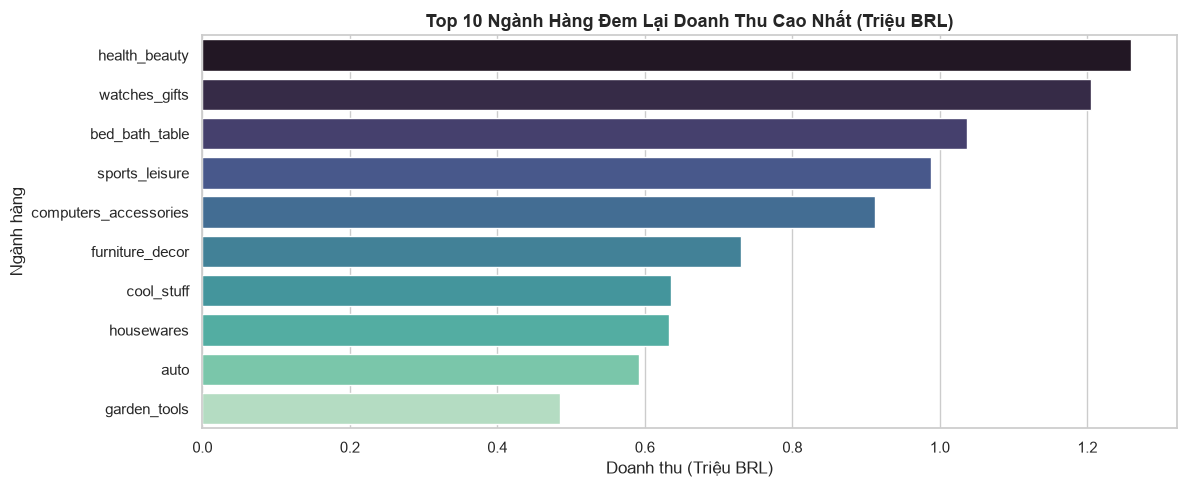

In [11]:
# Kết hợp order_items, products và translation để xem Top ngành hàng
df_items_prod = df_order_items[['order_id', 'product_id', 'price', 'freight_value']].merge(
    df_products[['product_id', 'product_category_name']], on='product_id', how='left'
).merge(
    df_translation, on='product_category_name', how='left'
)

# Điền giá trị thiếu cho tên tiếng Anh nếu không có bản dịch
df_items_prod['category_english'] = df_items_prod['product_category_name_english'].fillna(
    df_items_prod['product_category_name']
).fillna("other")

top_categories = df_items_prod.groupby('category_english')['price'].agg(['sum', 'count']).sort_values('sum', ascending=False).head(10)

plt.figure(figsize=(12, 5))
sns.barplot(x=top_categories['sum'] / 1e6, y=top_categories.index, hue=top_categories.index, palette="mako", legend=False)
plt.title("Top 10 Ngành Hàng Đem Lại Doanh Thu Cao Nhất (Triệu BRL)", fontsize=13, fontweight='bold')
plt.xlabel("Doanh thu (Triệu BRL)")
plt.ylabel("Ngành hàng")
plt.tight_layout()
plt.show()

## 7. Đúc kết Kết quả & Kế hoạch Thực hiện Tiếp theo (Action Items)

Sau khi hoàn tất EDA tổng quan 9 bảng dữ liệu Olist, nhóm thống nhất các kết luận quan trọng sau:

| STT | Vấn đề / Phát hiện từ Dữ liệu | Giải pháp & Kế hoạch Thực hiện | Người phụ trách |
| :--- | :--- | :--- | :--- |
| **1** | **Khóa định danh khách hàng:** `customer_id` chỉ là mã đơn hàng, `customer_unique_id` mới là khách hàng thực sự. | Toàn bộ các bảng đặc trưng (RFM, trải nghiệm) và gộp dữ liệu **bắt buộc group by `customer_unique_id`**. | Cả nhóm (A, B, C) |
| **2** | **Tỷ lệ khách mua lặp lại cực thấp (~3.01%):** Gần 97% khách hàng chỉ mua 1 lần trong suốt 2 năm. | Phân khúc khách hàng không thể chỉ dựa vào Frequency truyền thống. Cần kết hợp: **Monetary, Recency, Phí vận chuyển (`freight_ratio`), và Điểm số trải nghiệm/đánh giá**. | C & B |
| **3** | **Lọc đơn hàng:** Đơn hàng `delivered` chiếm 97.02%, các đơn hủy/chờ xử lý thiếu ngày giao hàng và review. | Trong Task A03 & A04, nhóm sẽ **lọc giữ lại các đơn `delivered`** để đảm bảo tính toán thời gian giao hàng và đặc trưng chính xác. | A |
| **4** | **Trùng lặp khi Join (1-to-many):** 1 đơn hàng có thể có nhiều items (`order_items`), nhiều lần thanh toán (`order_payments`), hoặc nhiều review. | Khi join các bảng về cấp đơn hàng hoặc khách hàng, cần `aggregate` trước (sum price, sum freight, mean review_score) để tránh bùng nổ số dòng. | A (Task A03) |
| **5** | **Giao hàng trễ hạn (~8%):** Có mối liên hệ mật thiết giữa giao hàng trễ và đánh giá 1 sao. | Thành viên B sẽ khai thác sâu mối quan hệ giữa `delay_days`, `freight_ratio` với điểm đánh giá và xây dựng ngưỡng dịch vụ. | B (Task B03 - B08) |

---
*Notebook được biên soạn phục vụ đồ án Khai thác Dữ liệu (KTDL) - Nhóm phân khúc khách hàng Olist.*